# NB1 — Stage-2 Severity: Data Preparation & Ordinal Splits
**Pipeline:** Binary Classification ➜ **[YOU ARE HERE] Severity Classification (AKIEC / BCC / SCC / MEL)**

| Stage | Label | Disease | Clinical Severity |
|-------|-------|---------|-------------------|
| 0 | AKIEC | Actinic Keratosis / SCC in-situ | Pre-cancerous |
| 1 | BCC   | Basal Cell Carcinoma | Malignant, localized |
| 2 | SCC   | Squamous Cell Carcinoma | Malignant, invasive |
| 3 | MEL   | Melanoma | Highly malignant, metastatic |

**ISIC 2019 Metadata Fields Used:**
- `image` — unique image identifier (joins ground-truth + metadata CSVs)
- `patient_id` or `lesion_id` — used for GroupKFold to prevent data leakage
- `age_approx` — patient age (metadata feature, filled with median if NaN)
- `sex` — patient sex (one-hot encoded)
- `anatom_site_general` — body site of lesion (one-hot encoded)

In [1]:
# ─────────────────────────────────────────────────────────────────
# CELL 1 ─ Imports & Configuration
# ─────────────────────────────────────────────────────────────────
import os, cv2, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from collections import Counter
from sklearn.model_selection import StratifiedGroupKFold
from tqdm.auto import tqdm

warnings.filterwarnings('ignore')

# ── Kaggle ISIC 2019 paths ────────────────────────────────────────
ISIC_IMAGES_DIR  = Path('/kaggle/input/datasets/andrewmvd/isic-2019/ISIC_2019_Training_Input/ISIC_2019_Training_Input')
GROUND_TRUTH_CSV = Path('/kaggle/input/datasets/andrewmvd/isic-2019/ISIC_2019_Training_GroundTruth.csv')
METADATA_CSV     = Path('/kaggle/input/datasets/andrewmvd/isic-2019/ISIC_2019_Training_Metadata.csv')
OUTPUT_DIR       = Path('/kaggle/working/severity_data')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ── CORAL ordinal severity stages ────────────────────────────────
MALIGNANT_CLASSES = ['AK', 'BCC', 'SCC', 'MEL']
SEVERITY_MAP      = {'AK': 0, 'BCC': 1, 'SCC': 2, 'MEL': 3}
N_FOLDS, IMAGE_SIZE, RANDOM_SEED = 5, 224, 42

print('✅ Imports complete.')
print(f'   Images dir : {ISIC_IMAGES_DIR}')
print(f'   Output dir : {OUTPUT_DIR}')

✅ Imports complete.
   Images dir : /kaggle/input/datasets/andrewmvd/isic-2019/ISIC_2019_Training_Input/ISIC_2019_Training_Input
   Output dir : /kaggle/working/severity_data


In [2]:
# ─────────────────────────────────────────────────────────────────
# CELL 2 ─ Load & Merge ISIC 2019 Ground Truth + Metadata
# Ground truth CSV has one-hot columns: MEL, NV, BCC, AKIEC, BKL, DF, VASC, SCC, UNK
# Metadata CSV has: image, age_approx, sex, anatom_site_general, lesion_id (maybe patient_id)
# ─────────────────────────────────────────────────────────────────
gt_df   = pd.read_csv(GROUND_TRUTH_CSV)
meta_df = pd.read_csv(METADATA_CSV)

print('Ground Truth shape :', gt_df.shape)
print('Ground Truth columns:', gt_df.columns.tolist())
print('Metadata shape     :', meta_df.shape)
print('Metadata columns   :', meta_df.columns.tolist())

# Convert one-hot → single string label (take the column name where value == 1.0)
diag_cols = [c for c in ['MEL','NV','BCC','AK','BKL','DF','VASC','SCC','UNK']
             if c in gt_df.columns]
gt_df['diagnosis'] = gt_df[diag_cols].idxmax(axis=1)

# Merge on 'image' key
df = gt_df[['image', 'diagnosis']].merge(meta_df, on='image', how='left')
print(f'\nMerged shape: {df.shape}')
print(df.head(3))
print('\nFull class distribution:')
print(df['diagnosis'].value_counts())

Ground Truth shape : (25331, 10)
Ground Truth columns: ['image', 'MEL', 'NV', 'BCC', 'AK', 'BKL', 'DF', 'VASC', 'SCC', 'UNK']
Metadata shape     : (25331, 5)
Metadata columns   : ['image', 'age_approx', 'anatom_site_general', 'lesion_id', 'sex']

Merged shape: (25331, 6)
          image diagnosis  age_approx anatom_site_general lesion_id     sex
0  ISIC_0000000        NV        55.0      anterior torso       NaN  female
1  ISIC_0000001        NV        30.0      anterior torso       NaN  female
2  ISIC_0000002       MEL        60.0     upper extremity       NaN  female

Full class distribution:
diagnosis
NV      12875
MEL      4522
BCC      3323
BKL      2624
AK        867
SCC       628
VASC      253
DF        239
Name: count, dtype: int64


Full dataset    : 25,331 images
Malignant only  : 9,340 images
Dropped (benign): 15,991 images


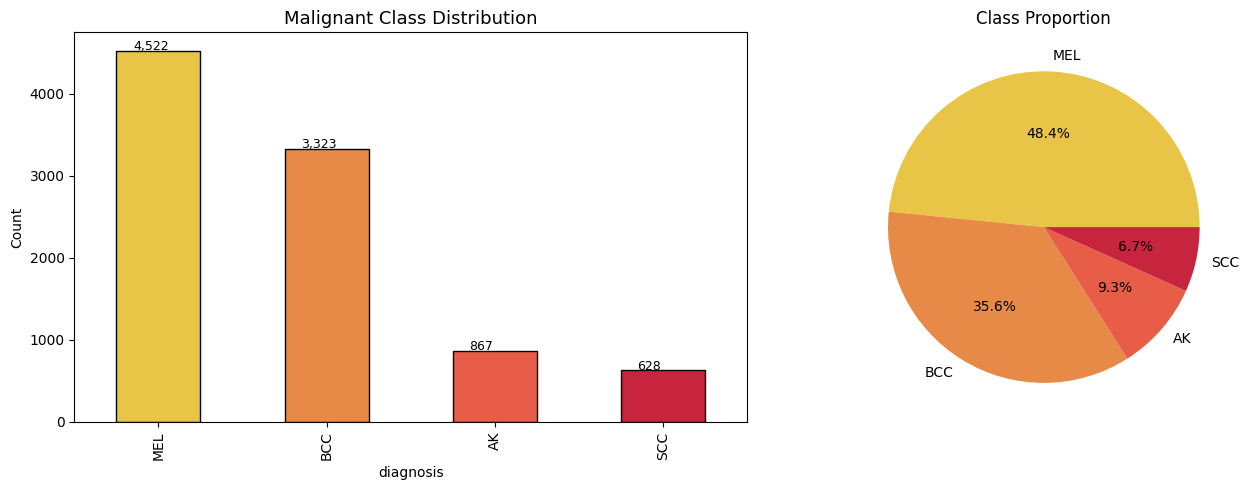

In [3]:
# ─────────────────────────────────────────────────────────────────
# CELL 3 ─ STRICT MALIGNANT FILTERING (Critical for Stage-2)
# Drop benign: NV, BKL, DF, VASC, UNK. Keep: AKIEC, BCC, SCC, MEL
# ─────────────────────────────────────────────────────────────────
severity_df = df[df['diagnosis'].isin(MALIGNANT_CLASSES)].copy()
severity_df.reset_index(drop=True, inplace=True)

print(f'Full dataset    : {len(df):,} images')
print(f'Malignant only  : {len(severity_df):,} images')
print(f'Dropped (benign): {len(df) - len(severity_df):,} images')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
counts = severity_df['diagnosis'].value_counts()
colors = ['#e8c547', '#e88a47', '#e85d47', '#c7253e']

counts.plot(kind='bar', ax=axes[0], color=colors, edgecolor='black')
axes[0].set_title('Malignant Class Distribution', fontsize=13)
axes[0].set_ylabel('Count')
for p in axes[0].patches:
    axes[0].text(p.get_x() + 0.1, p.get_height() + 10, f'{int(p.get_height()):,}', fontsize=9)

axes[1].pie(counts, labels=counts.index, autopct='%1.1f%%', colors=colors)
axes[1].set_title('Class Proportion')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'class_distribution.png', dpi=120)
plt.show()

In [4]:
# ─────────────────────────────────────────────────────────────────
# CELL 4 ─ ORDINAL LABEL MAPPING + METADATA FEATURE ENGINEERING
# ─────────────────────────────────────────────────────────────────
severity_df['ordinal_label'] = severity_df['diagnosis'].map(SEVERITY_MAP)

# ── age_approx: fill NaN with median, normalise to [0,1] ─────────
if 'age_approx' in severity_df.columns:
    median_age = severity_df['age_approx'].median()
    severity_df['age_approx'] = severity_df['age_approx'].fillna(median_age)
    severity_df['age_norm']   = (severity_df['age_approx'] / 85.0).clip(0, 1)
else:
    severity_df['age_norm'] = 0.5

# ── sex: binary encode ───────────────────────────────────────────
if 'sex' in severity_df.columns:
    severity_df['sex_male']   = (severity_df['sex'] == 'male').astype(float)
    severity_df['sex_female'] = (severity_df['sex'] == 'female').astype(float)
else:
    severity_df['sex_male'] = 0.0
    severity_df['sex_female'] = 0.0

# ── anatom_site: one-hot encode ──────────────────────────────────
site_col = 'anatom_site_general' if 'anatom_site_general' in severity_df.columns else None
if site_col:
    severity_df[site_col] = severity_df[site_col].fillna('unknown')
    site_dummies = pd.get_dummies(severity_df[site_col], prefix='site')
    severity_df  = pd.concat([severity_df, site_dummies], axis=1)

# ── Verify image paths ───────────────────────────────────────────
severity_df['image_path'] = severity_df['image'].apply(
    lambda x: str(ISIC_IMAGES_DIR / f'{x}.jpg'))
missing = (~severity_df['image_path'].apply(Path).apply(Path.exists)).sum()
print(f'Missing image files: {missing}')

print('\n✅ Label mapping + metadata engineering complete:')
print(severity_df[['image','diagnosis','ordinal_label','age_norm','sex_male']].head(5))

Missing image files: 0

✅ Label mapping + metadata engineering complete:
                      image diagnosis  ordinal_label  age_norm  sex_male
0              ISIC_0000002       MEL              3  0.705882       0.0
1              ISIC_0000004       MEL              3  0.941176       1.0
2              ISIC_0000013       MEL              3  0.352941       0.0
3  ISIC_0000022_downsampled       MEL              3  0.647059       0.0
4  ISIC_0000026_downsampled       MEL              3  0.352941       0.0


In [5]:
# ─────────────────────────────────────────────────────────────────
# CELL 5 ─ STATIC PREPROCESSING: DullRazor + Shades of Gray
# Pre-process once → save to disk → training reads pre-clean images
# This saves repeated CPU overhead in every training epoch.
# ─────────────────────────────────────────────────────────────────
def dull_razor(image: np.ndarray, kernel_size: int = 9) -> np.ndarray:
    """Remove dermoscope hair artifacts via morphological blackhat + inpainting."""
    gray     = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    kernel   = cv2.getStructuringElement(cv2.MORPH_RECT, (kernel_size, kernel_size))
    blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)
    _, mask  = cv2.threshold(blackhat, 10, 255, cv2.THRESH_BINARY)
    return cv2.inpaint(image, mask, inpaintRadius=6, flags=cv2.INPAINT_TELEA)

def shades_of_gray(image: np.ndarray, power: float = 6.0) -> np.ndarray:
    """Shades of Grey color constancy — reduces device/lighting variance."""
    img  = image.astype(np.float32) + 1e-8
    norm = np.power(np.mean(np.power(img, power), axis=(0, 1)), 1.0 / power)
    scale = norm / (np.mean(norm) + 1e-8)
    return np.clip(img / (scale + 1e-8), 0, 255).astype(np.uint8)

PREPROCESSED_DIR = OUTPUT_DIR / 'preprocessed_images'
PREPROCESSED_DIR.mkdir(parents=True, exist_ok=True)

def preprocess_and_save(row) -> str:
    src = Path(row['image_path'])
    dst = PREPROCESSED_DIR / src.name
    if dst.exists():
        return str(dst)                      # skip if already done
    img = cv2.imread(str(src))
    if img is None:
        return str(src)                      # fallback to original
    try:
        img = dull_razor(img)
        img = shades_of_gray(img)
    except Exception:
        pass                                  # keep original if pre-process fails
    img = cv2.resize(img, (IMAGE_SIZE, IMAGE_SIZE))
    cv2.imwrite(str(dst), img)
    return str(dst)

print(f'Pre-processing {len(severity_df):,} malignant images ...')
tqdm.pandas()
severity_df['preprocessed_path'] = severity_df.progress_apply(preprocess_and_save, axis=1)
print('✅ Static preprocessing complete.')

Pre-processing 9,340 malignant images ...


  0%|          | 0/9340 [00:00<?, ?it/s]

✅ Static preprocessing complete.


In [6]:
# ─────────────────────────────────────────────────────────────────
# CELL 6 ─ PATIENT-STRATIFIED GROUP K-FOLD (prevents data leakage)
# Priority: lesion_id > patient_id > image-prefix fallback
# ─────────────────────────────────────────────────────────────────
if 'lesion_id' in severity_df.columns and severity_df['lesion_id'].notna().any():
    group_col = 'lesion_id'
elif 'patient_id' in severity_df.columns and severity_df['patient_id'].notna().any():
    group_col = 'patient_id'
else:
    print('⚠️  No patient/lesion ID — using image prefix as group (last resort).')
    severity_df['_grp'] = severity_df['image'].str[:15]
    group_col = '_grp'

# Fill remaining NaN groups with the image name itself
severity_df[group_col] = severity_df[group_col].fillna(severity_df['image'])

print(f'Group key      : {group_col}')
print(f'Unique groups  : {severity_df[group_col].nunique():,}')

sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_SEED)
severity_df['fold'] = -1

for fold_idx, (_, val_idx) in enumerate(
    sgkf.split(severity_df, severity_df['ordinal_label'], groups=severity_df[group_col])
):
    severity_df.loc[val_idx, 'fold'] = fold_idx

assert (severity_df['fold'] == -1).sum() == 0, 'Some rows have no fold assignment!'

print('\n✅ Fold assignment complete:')
print(severity_df['fold'].value_counts().sort_index())
print('\nClass × Fold cross-table:')
print(severity_df.groupby('fold')['diagnosis'].value_counts().unstack().fillna(0).astype(int))

Group key      : lesion_id
Unique groups  : 3,572

✅ Fold assignment complete:
fold
0    1885
1    1803
2    1849
3    1996
4    1807
Name: count, dtype: int64

Class × Fold cross-table:
diagnosis   AK  BCC   MEL  SCC
fold                          
0          160  700   904  121
1          144  686   820  153
2          199  628   915  107
3          181  670  1048   97
4          183  639   835  150


✅ Saved: /kaggle/working/severity_data/severity_train_folds.csv  |  rows=9,340  |  cols=17
Ordinal label distribution in saved CSV:
ordinal_label
0     867
1    3323
2     628
3    4522
Name: count, dtype: int64


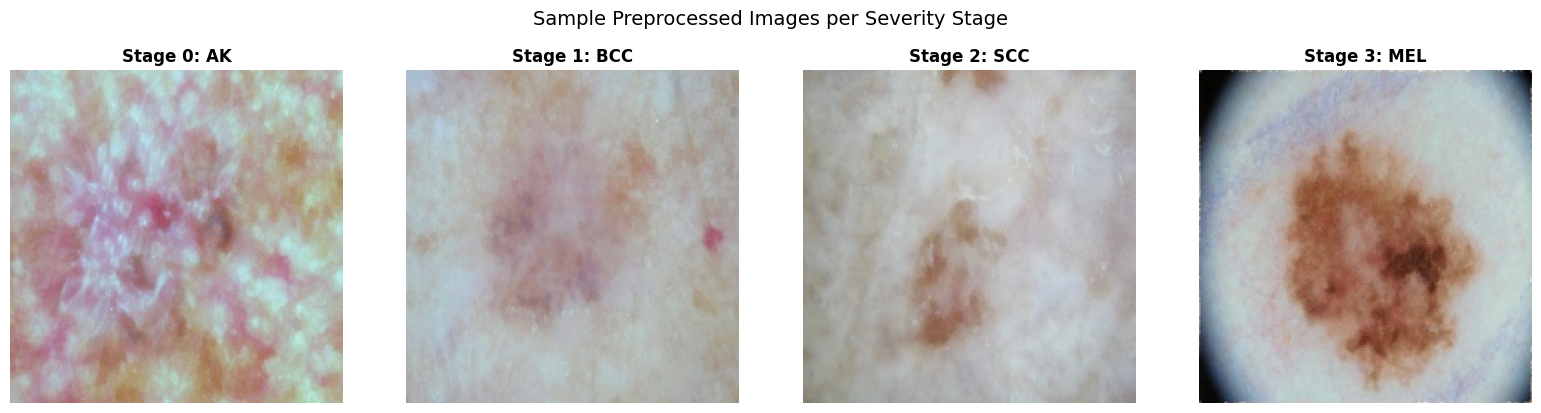


🏁 NB1 complete — run NB2, NB3, NB4 independently for model training.


In [7]:
# ─────────────────────────────────────────────────────────────────
# CELL 7 ─ EXPORT CSV + VISUAL VERIFICATION
# ─────────────────────────────────────────────────────────────────
save_cols = (
    ['image', 'preprocessed_path', 'diagnosis', 'ordinal_label', 'fold',
     'age_norm', 'sex_male', 'sex_female']
    + [c for c in severity_df.columns if c.startswith('site_')]
)
# Keep only columns that actually exist
save_cols = [c for c in save_cols if c in severity_df.columns]

out_csv = OUTPUT_DIR / 'severity_train_folds.csv'
severity_df[save_cols].to_csv(out_csv, index=False)
print(f'✅ Saved: {out_csv}  |  rows={len(severity_df):,}  |  cols={len(save_cols)}')

# Verify round-trip read
verify = pd.read_csv(out_csv)
assert len(verify) == len(severity_df), 'Row count mismatch after CSV save!'
print('Ordinal label distribution in saved CSV:')
print(verify['ordinal_label'].value_counts().sort_index())

# Sample image preview
sample = severity_df.groupby('ordinal_label').first().reset_index()
fig, axes = plt.subplots(1, len(sample), figsize=(16, 4))
for ax, row in zip(axes, sample.itertuples()):
    img = cv2.cvtColor(cv2.imread(row.preprocessed_path), cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    ax.set_title(f'Stage {row.ordinal_label}: {row.diagnosis}', fontsize=12, fontweight='bold')
    ax.axis('off')
plt.suptitle('Sample Preprocessed Images per Severity Stage', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'sample_images.png', dpi=120, bbox_inches='tight')
plt.show()
print('\n🏁 NB1 complete — run NB2, NB3, NB4 independently for model training.')